In [21]:
import torch
from torch import nn, optim, functional as F
from torchvision import datasets, transforms
from torch.nn import functional as F
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch_size = 256

trainset = datasets.MNIST("./dataset/", train = True, transform = transforms.ToTensor(), download = True)
#dataloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = 2)

testset = datasets.MNIST("./dataset/", train = False, transform = transforms.ToTensor(), download =   True)
#testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = 2)

dataset = torch.utils.data.ConcatDataset([trainset, testset])
dataloader = torch.utils.data.DataLoader(
	dataset,
	batch_size = batch_size,
	shuffle = True
)

tensor_to_img = transforms.ToPILImage()

## VAE

### Train

In [23]:
activation_func = "VAE"

class VAE(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 500),
            nn.ReLU(),
            nn.Linear(500, 500),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(500, latent_dim)
        self.fc_logvar = nn.Linear(500, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 500),
            nn.ReLU(),
            nn.Linear(500, 500),
            nn.ReLU(),
            nn.Linear(500, 28 * 28),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvae = self.fc_logvar(h)
        return mu, logvae
    
    def decode(self, z):
        return self.decoder(z)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_reconstructed = self.decode(z)
        return (x_reconstructed, mu, logvar)

In [24]:
model = VAE()
model.to(device)

pretrain_epochs = 400

#loss_function = nn.BCELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-3,
    weight_decay = 1e-4
)

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    batch_recons = []
    batch_kls = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        reconstructed = model(images)

        # Reconstruction loss
        recon_loss = F.binary_cross_entropy_with_logits(
            reconstructed[0],
            images,
            reduction = "sum"
        ) / images.size(0)

        # KL Divergence
        kl_loss = -0.5 * torch.sum(1 + reconstructed[2] - reconstructed[1]**2 - reconstructed[2].exp(), dim = 1).mean()

        # Total Loss (ELBO)
        loss = recon_loss + (1.0 * kl_loss)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
        batch_recons.append(recon_loss.item())
        batch_kls.append(kl_loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(
        f"Epoch {epoch+1}/{pretrain_epochs} | "
        f"loss = {sum(batch_losses)/len(batch_losses):.4f} | "
        f"recon = {sum(batch_recons)/len(batch_recons):.4f} | "
        f"kl = {sum(batch_kls)/len(batch_kls):.4f}"
    )

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Epoch 1/400 | loss=190.3369 | recon=185.3668 | kl=4.9701
Best Train Epoch: 1/400, Loss: 190.336900
Epoch 2/400 | loss=135.2655 | recon=122.9676 | kl=12.2980
Best Train Epoch: 2/400, Loss: 135.265526
Epoch 3/400 | loss=122.1571 | recon=107.4111 | kl=14.7460
Best Train Epoch: 3/400, Loss: 122.157101
Epoch 4/400 | loss=115.2281 | recon=98.8833 | kl=16.3448
Best Train Epoch: 4/400, Loss: 115.228143
Epoch 5/400 | loss=111.8077 | recon=94.8188 | kl=16.9889
Best Train Epoch: 5/400, Loss: 111.807688
Epoch 6/400 | loss=109.6349 | recon=92.2900 | kl=17.3449
Best Train Epoch: 6/400, Loss: 109.634861
Epoch 7/400 | loss=108.1312 | recon=90.5122 | kl=17.6190
Best Train Epoch: 7/400, Loss: 108.131200
Epoch 8/400 | loss=106.9267 | recon=89.1597 | kl=17.7669
Best Train Epoch: 8/400, Loss: 106.926662
Epoch 9/400 | loss=105.9647 | recon=88.0320 | kl=17.9326
Best Train Epoch: 9/400, Loss: 105.964681
Epoch 10/400 | loss=105.1660 | recon=87.1158 | kl=18.0502
Best Train Epoch: 10/400, Loss: 105.166036
Epoch 

### Visualize

In [25]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = VAE()
model.to(device)

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=500, bias=True)
    (1): ReLU()
    (2): Linear(in_features=500, out_features=500, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=500, out_features=10, bias=True)
  (fc_logvar): Linear(in_features=500, out_features=10, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=10, out_features=500, bias=True)
    (1): ReLU()
    (2): Linear(in_features=500, out_features=500, bias=True)
    (3): ReLU()
    (4): Linear(in_features=500, out_features=784, bias=True)
  )
)

#### reconstructed from input

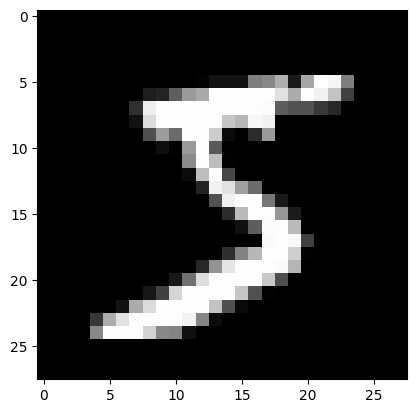

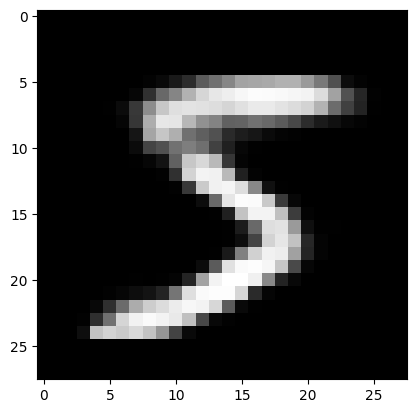

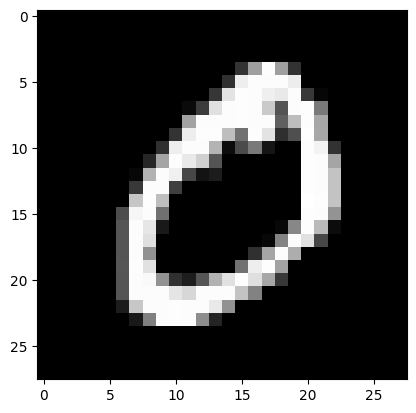

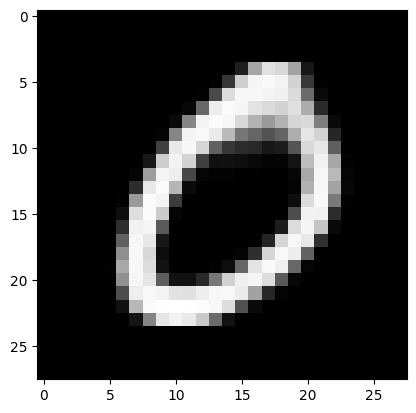

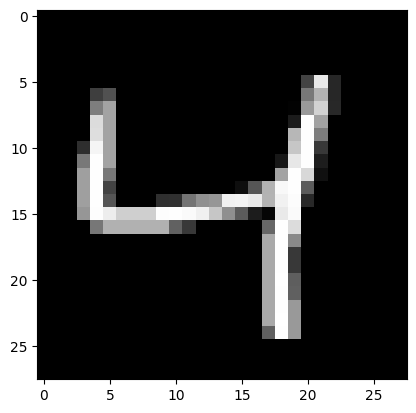

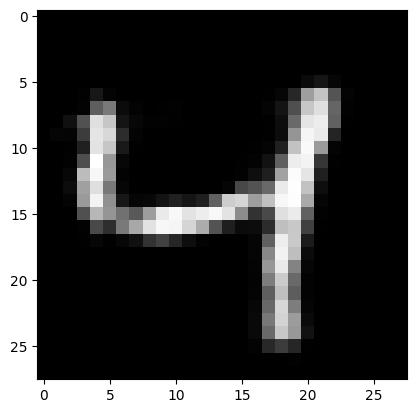

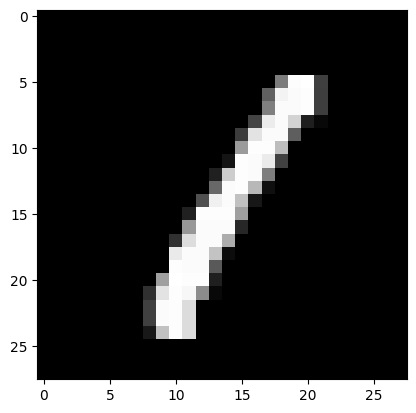

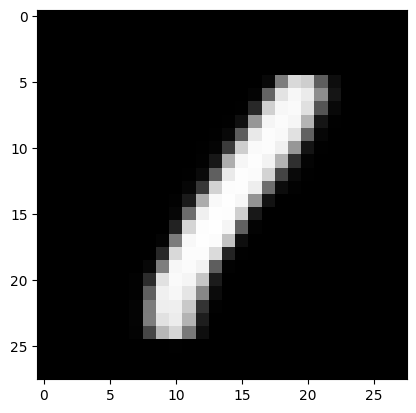

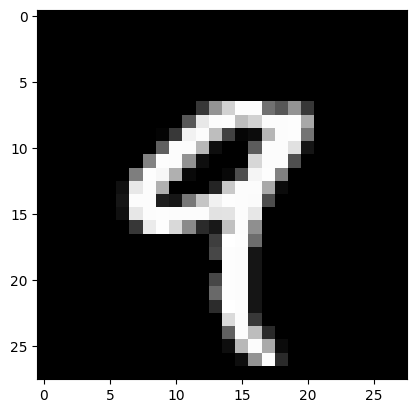

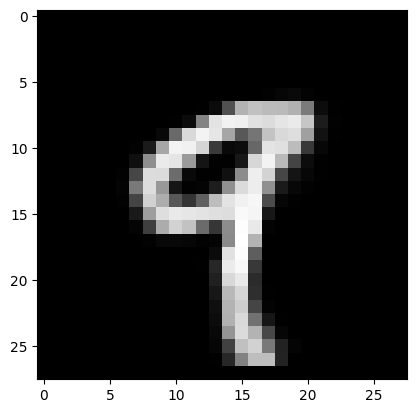

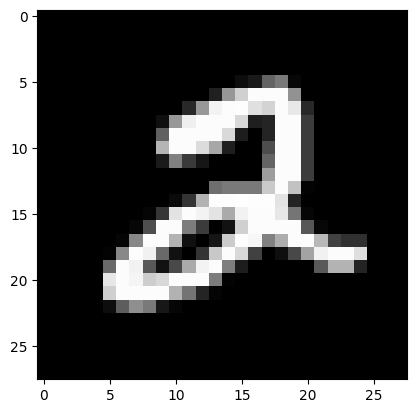

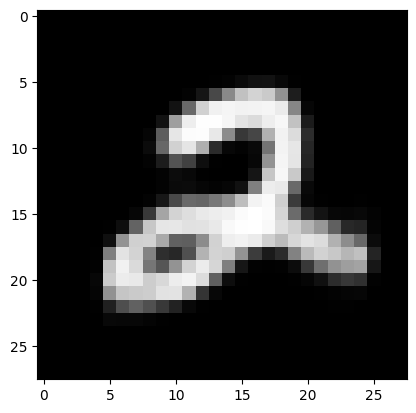

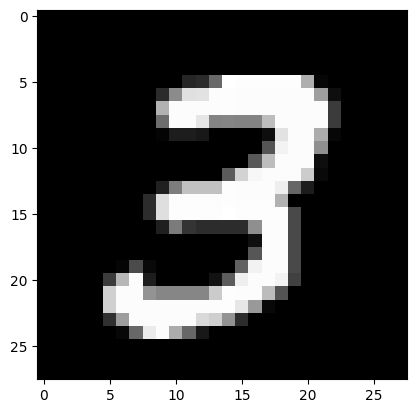

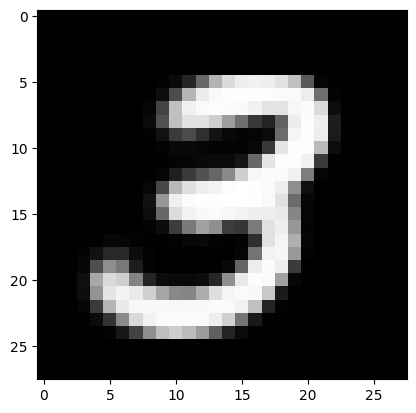

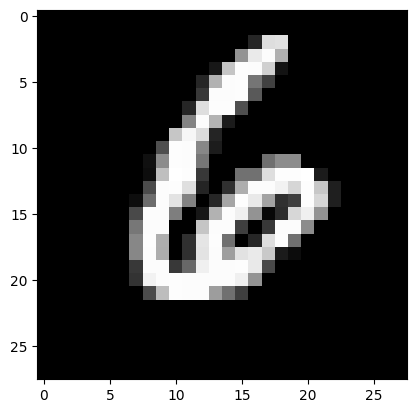

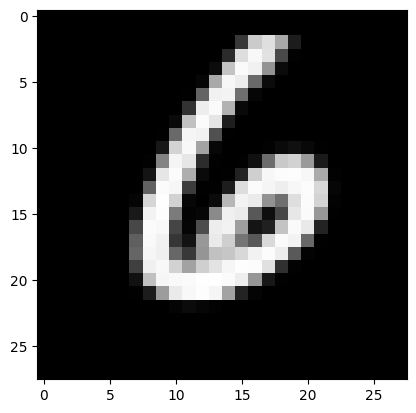

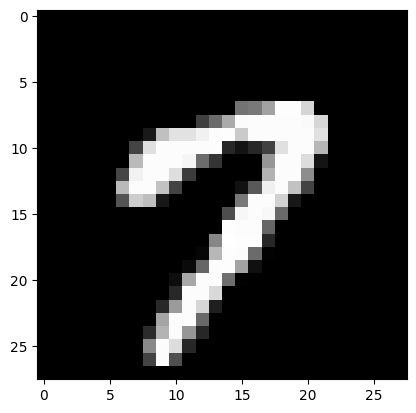

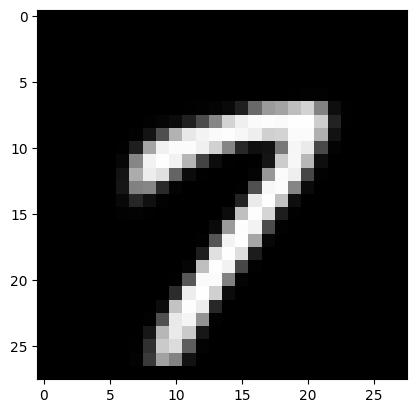

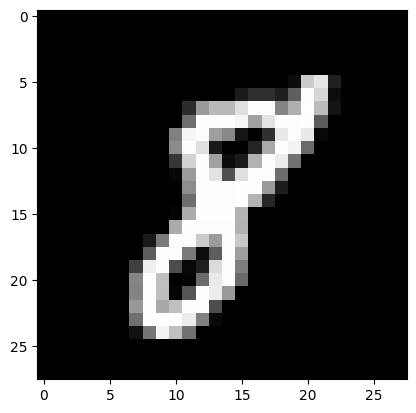

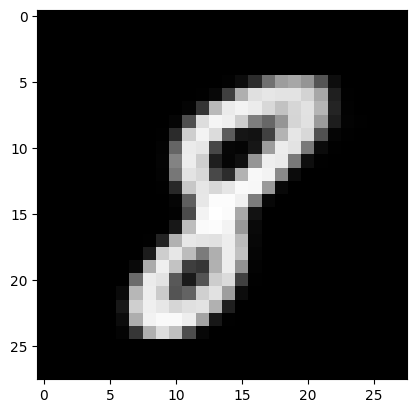

In [26]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)[0]
		reconstructed = torch.sigmoid(reconstructed)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Reconstructed from mean

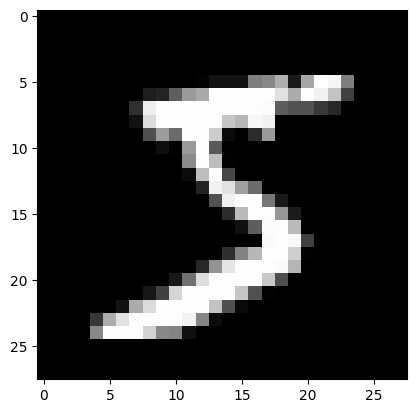

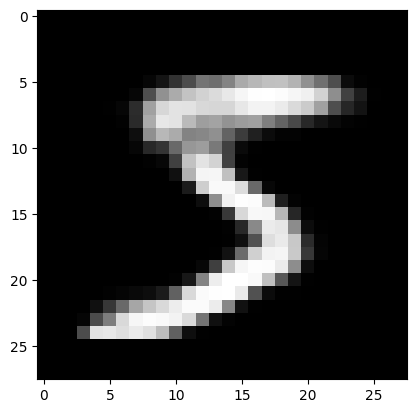

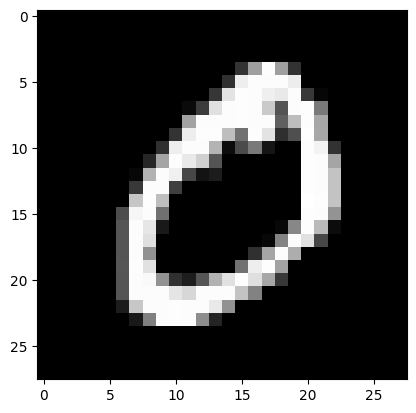

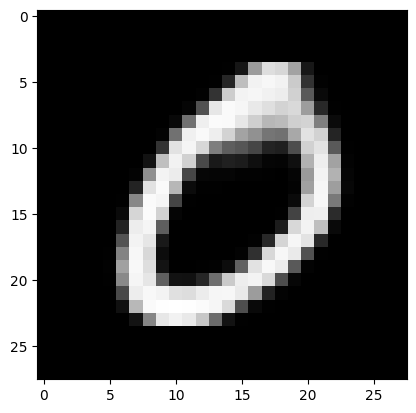

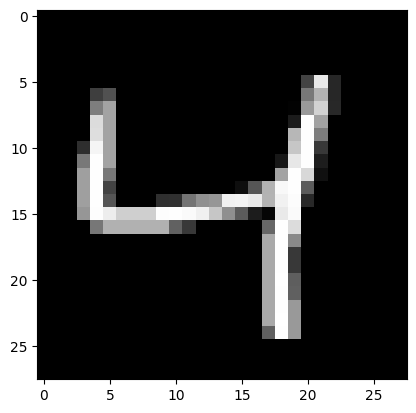

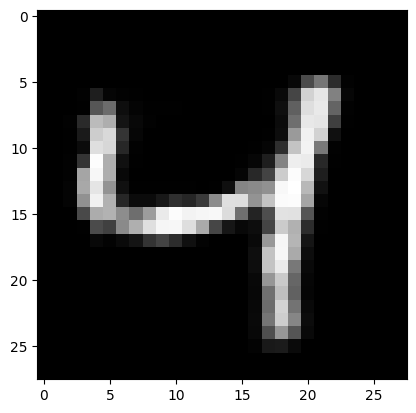

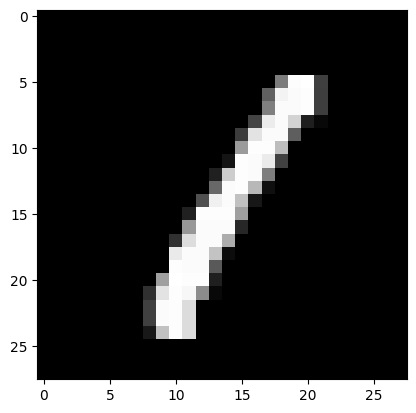

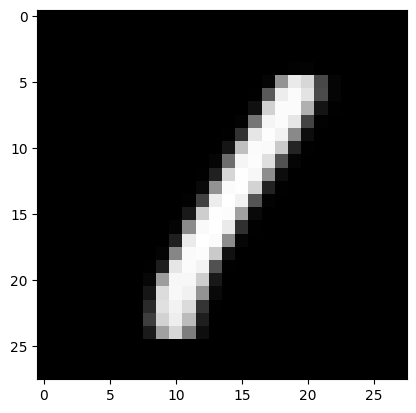

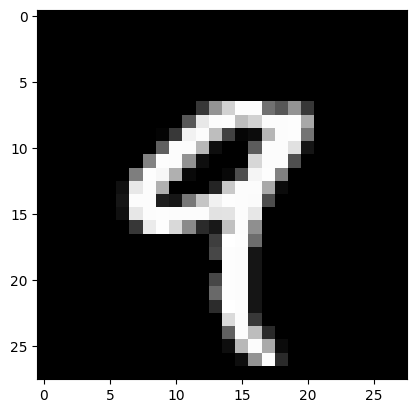

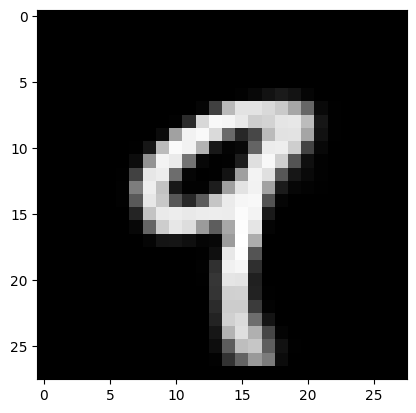

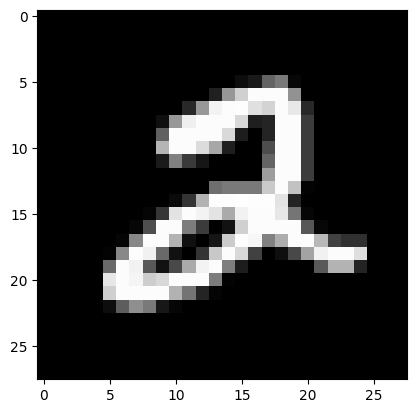

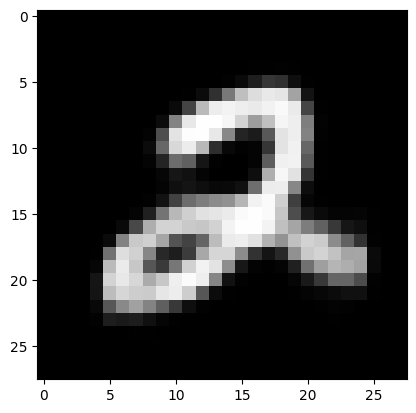

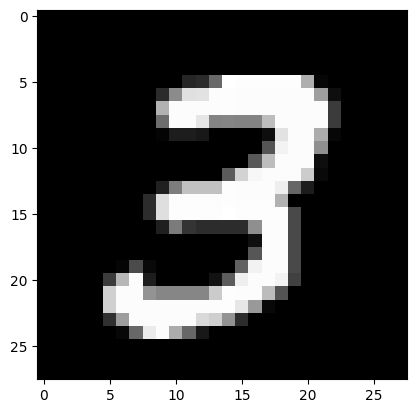

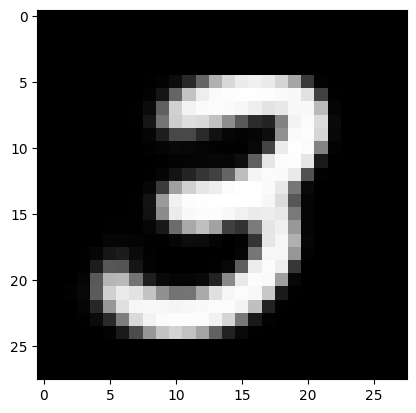

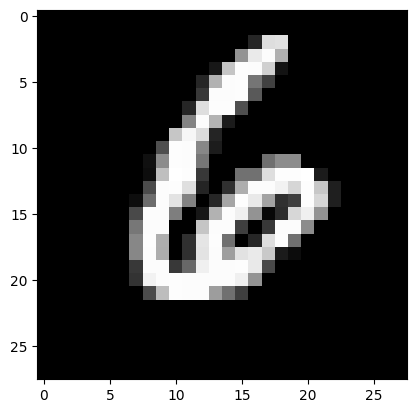

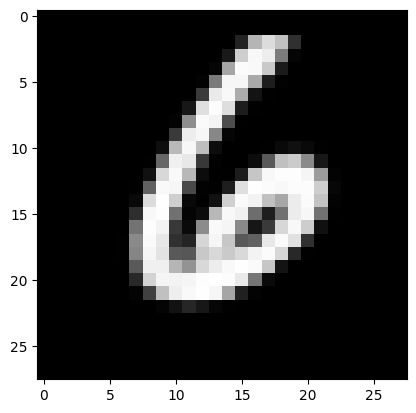

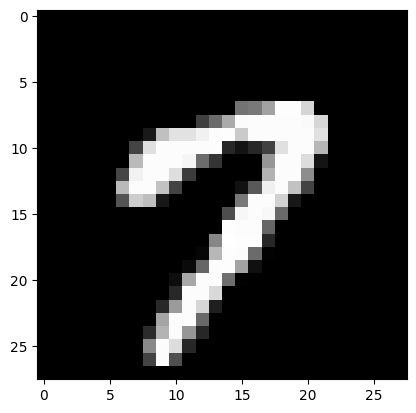

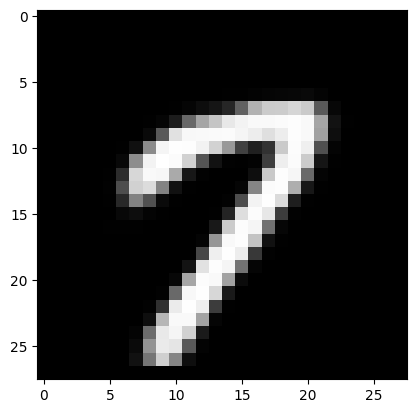

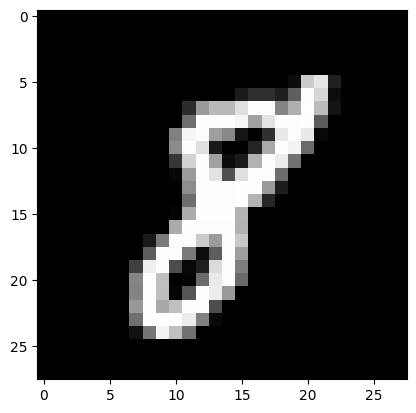

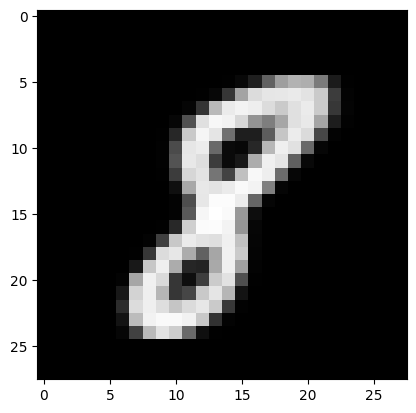

In [38]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		mu = model(image_tensor)[1]
		logits = model.decode(mu)
		reconstructed = torch.sigmoid(logits)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [89]:
model = VAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)[0]

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [90]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


"""scaler = StandardScaler()
Z = scaler.fit_transform(Z)"""

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [91]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6364
NMI: 0.6703


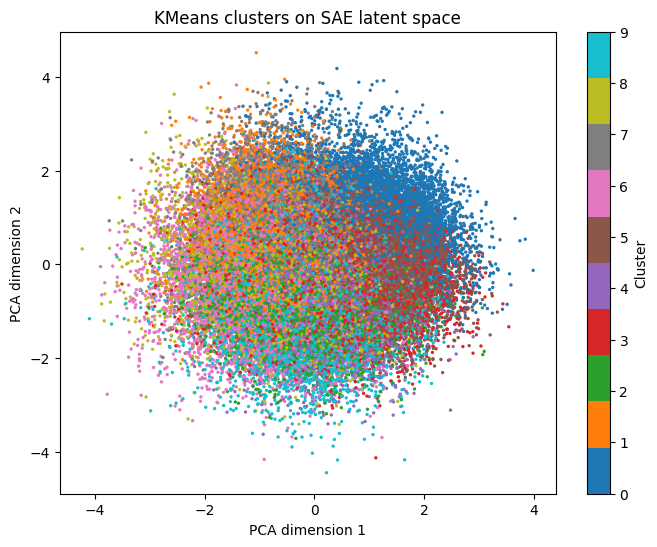

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on VAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

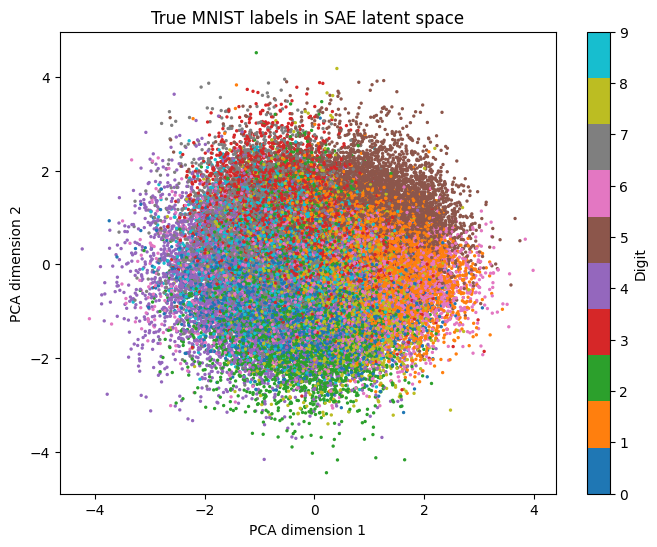

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in VAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [94]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


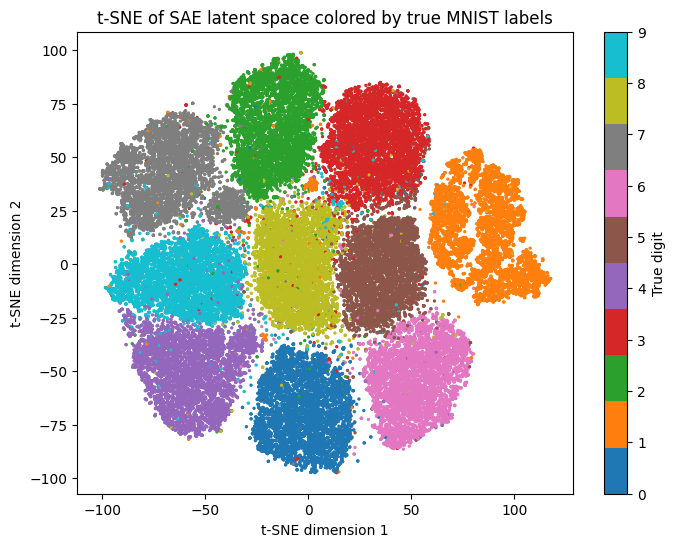

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of VAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

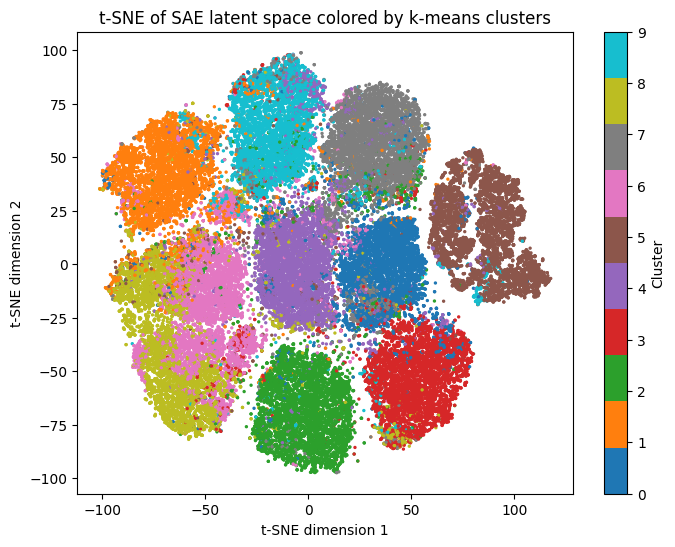

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of VAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [97]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.7868


In [98]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,84,84,51,234,16,4997,311,41,280,59
1,37,36,199,97,20,25,0,6016,45,703
2,6511,1,135,251,40,211,42,31,98,140
3,46,37,104,31,258,237,5946,0,55,2
4,24,85,526,300,23,136,114,71,5617,116
5,5,7358,31,28,40,14,20,75,113,195
6,25,45,58,86,2696,102,31,548,151,3454
7,70,18,285,5934,0,548,50,36,250,87
8,61,4,52,3,3696,40,251,144,192,2192


In [99]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.01,0.01,0.01,0.04,0.00,0.81,0.05,0.01,0.05,0.01
1,0.01,0.01,0.03,0.01,0.00,0.00,0.00,0.84,0.01,0.10
2,0.87,0.00,0.02,0.03,0.01,0.03,0.01,0.00,0.01,0.02
3,0.01,0.01,0.02,0.00,0.04,0.04,0.89,0.00,0.01,0.00
4,0.00,0.01,0.08,0.04,0.00,0.02,0.02,0.01,0.80,0.02
5,0.00,0.93,0.00,0.00,0.01,0.00,0.00,0.01,0.01,0.02
6,0.00,0.01,0.01,0.01,0.37,0.01,0.00,0.08,0.02,0.48
7,0.01,0.00,0.04,0.82,0.00,0.08,0.01,0.00,0.03,0.01
8,0.01,0.00,0.01,0.00,0.56,0.01,0.04,0.02,0.03,0.33


## VAE more complex

### Train

In [100]:
activation_func = "VAE_complex"

class VAE(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 500),
            nn.ReLU(),
            nn.Linear(500, 500),
            nn.ReLU(),
            nn.Linear(500, 2000),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(2000, latent_dim)
        self.fc_logvar = nn.Linear(2000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 2000),
            nn.ReLU(),
            nn.Linear(2000, 500),
            nn.ReLU(),
            nn.Linear(500, 500),
            nn.ReLU(),
            nn.Linear(500, 28 * 28),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvae = self.fc_logvar(h)
        return mu, logvae
    
    def decode(self, z):
        return self.decoder(z)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_reconstructed = self.decode(z)
        return (x_reconstructed, mu, logvar)

In [101]:
model = VAE()
model.to(device)

pretrain_epochs = 400

#loss_function = nn.BCELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-3,
    weight_decay = 1e-4
)

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    batch_recons = []
    batch_kls = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        reconstructed = model(images)

        recon_loss = F.binary_cross_entropy_with_logits(reconstructed[0], images, reduction = "none").sum(dim = 1).mean()

        # 2. KL Divergence
        # Analytic KL for Normal distributions
        kl_loss = -0.5 * torch.sum(1 + reconstructed[2] - reconstructed[1]**2 - reconstructed[2].exp(), dim = 1).mean()

        # 3. Total Loss (ELBO)
        loss = recon_loss + (1.0 * kl_loss)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
        batch_recons.append(recon_loss.item())
        batch_kls.append(kl_loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(
        f"Epoch {epoch+1}/{pretrain_epochs} | "
        f"loss = {sum(batch_losses)/len(batch_losses):.4f} | "
        f"recon = {sum(batch_recons)/len(batch_recons):.4f} | "
        f"kl = {sum(batch_kls)/len(batch_kls):.4f}"
    )

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Epoch 1/400 | loss=193.0880 | recon=189.4659 | kl=3.6221
Best Train Epoch: 1/400, Loss: 193.087997
Epoch 2/400 | loss=150.5773 | recon=143.0534 | kl=7.5238
Best Train Epoch: 2/400, Loss: 150.577272
Epoch 3/400 | loss=133.0687 | recon=122.7524 | kl=10.3163
Best Train Epoch: 3/400, Loss: 133.068718
Epoch 4/400 | loss=127.3622 | recon=116.6384 | kl=10.7238
Best Train Epoch: 4/400, Loss: 127.362233
Epoch 5/400 | loss=124.3315 | recon=113.1180 | kl=11.2134
Best Train Epoch: 5/400, Loss: 124.331494
Epoch 6/400 | loss=120.8829 | recon=108.7304 | kl=12.1525
Best Train Epoch: 6/400, Loss: 120.882892
Epoch 7/400 | loss=117.9725 | recon=105.3972 | kl=12.5753
Best Train Epoch: 7/400, Loss: 117.972512
Epoch 8/400 | loss=116.1326 | recon=103.3335 | kl=12.7990
Best Train Epoch: 8/400, Loss: 116.132556
Epoch 9/400 | loss=114.7601 | recon=101.7840 | kl=12.9761
Best Train Epoch: 9/400, Loss: 114.760077
Epoch 10/400 | loss=113.5777 | recon=100.4405 | kl=13.1372
Best Train Epoch: 10/400, Loss: 113.577669


### Visualize

In [102]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = VAE()
model.to(device)

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=500, bias=True)
    (1): ReLU()
    (2): Linear(in_features=500, out_features=500, bias=True)
    (3): ReLU()
    (4): Linear(in_features=500, out_features=2000, bias=True)
    (5): ReLU()
  )
  (fc_mu): Linear(in_features=2000, out_features=10, bias=True)
  (fc_logvar): Linear(in_features=2000, out_features=10, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=10, out_features=2000, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2000, out_features=500, bias=True)
    (3): ReLU()
    (4): Linear(in_features=500, out_features=500, bias=True)
    (5): ReLU()
    (6): Linear(in_features=500, out_features=784, bias=True)
  )
)

#### reconstructed from input

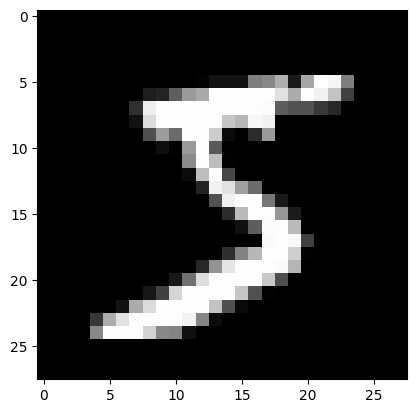

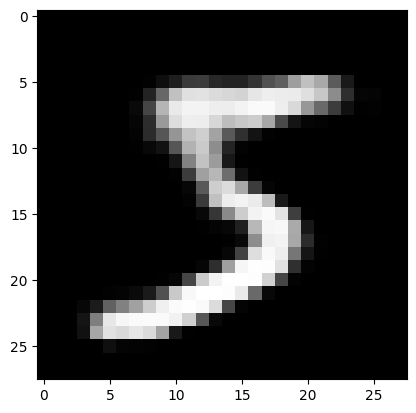

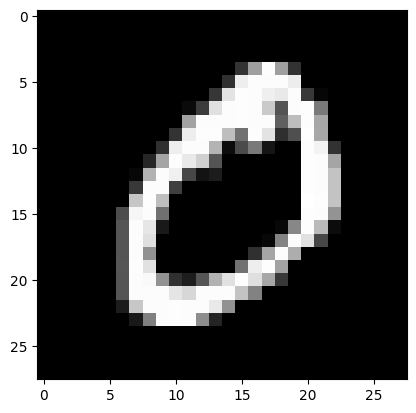

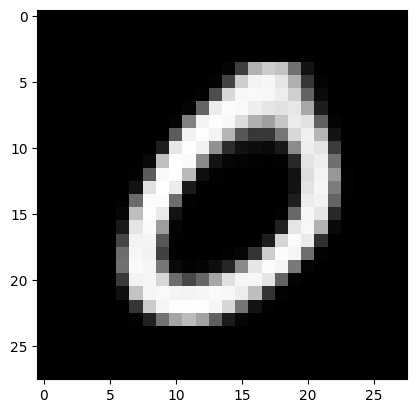

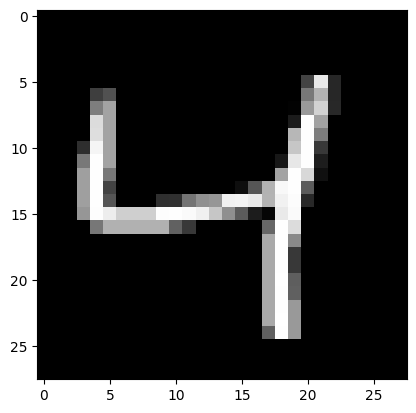

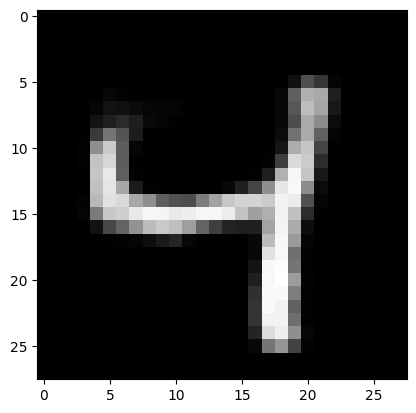

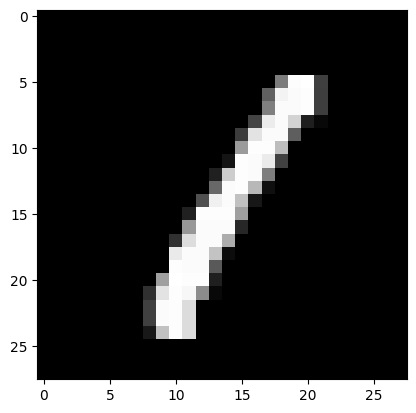

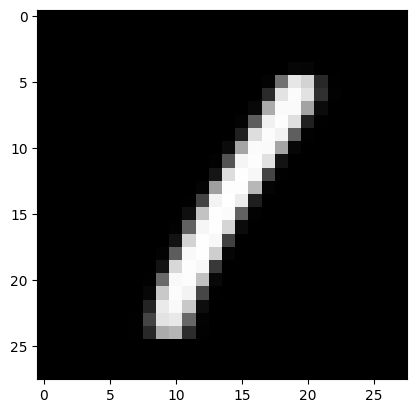

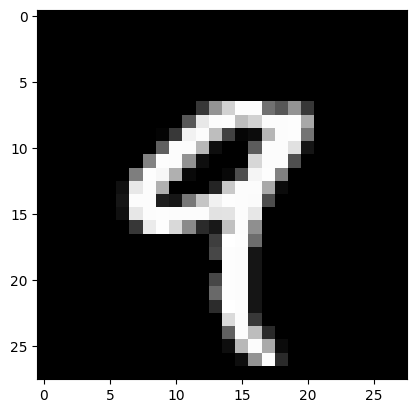

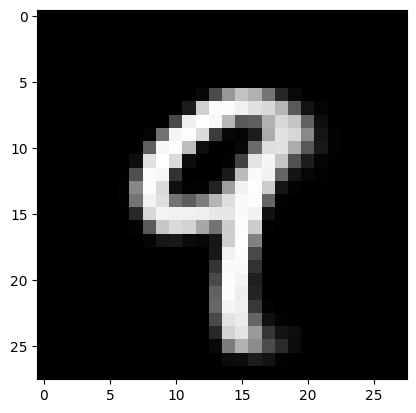

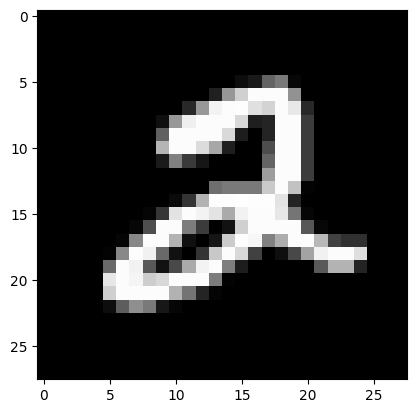

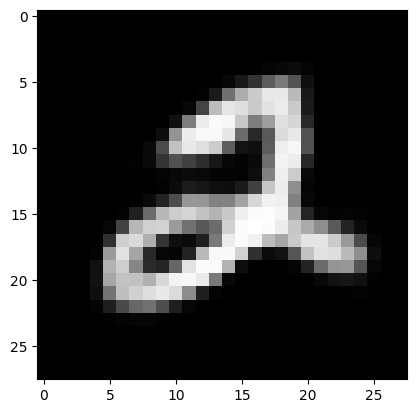

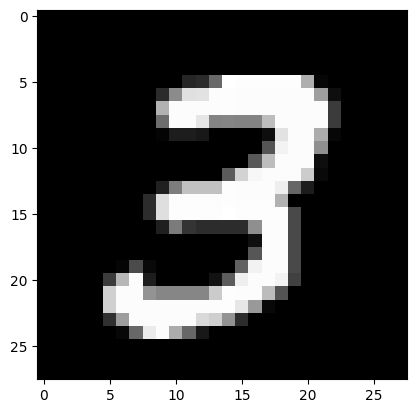

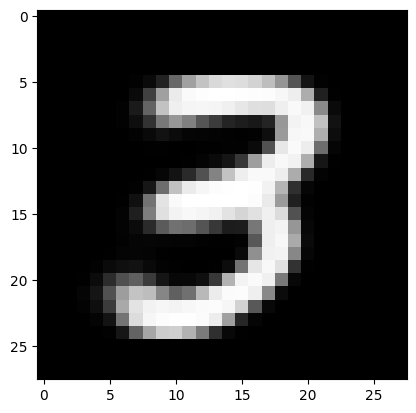

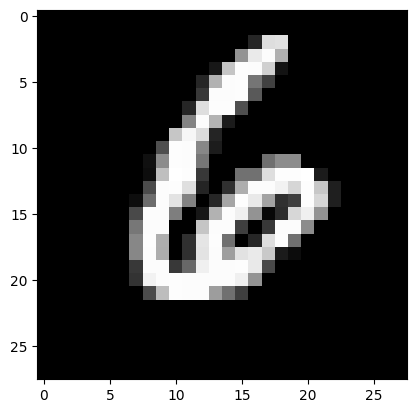

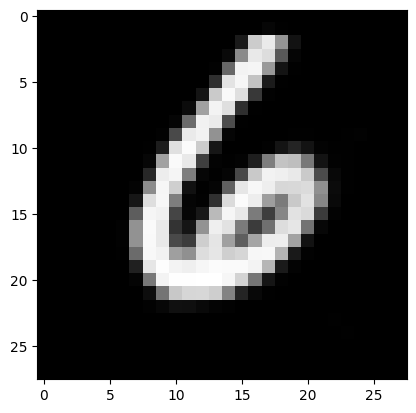

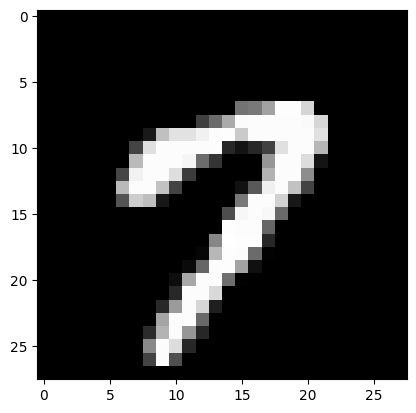

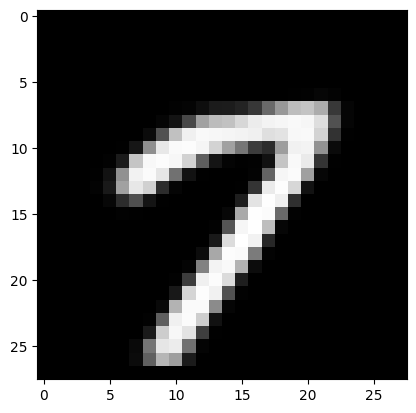

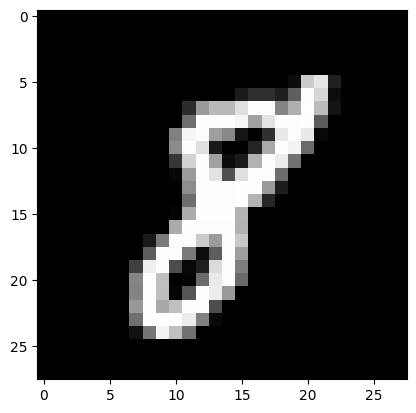

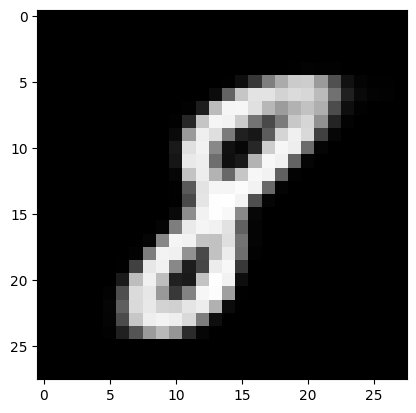

In [103]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)[0]
		reconstructed = torch.sigmoid(reconstructed)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Reconstructed from mean

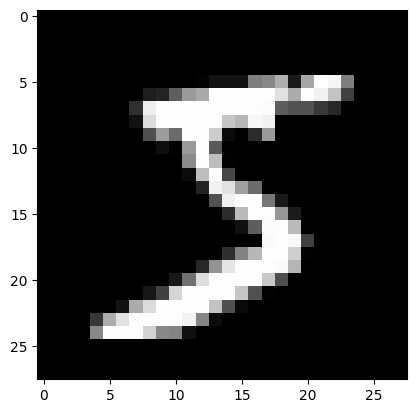

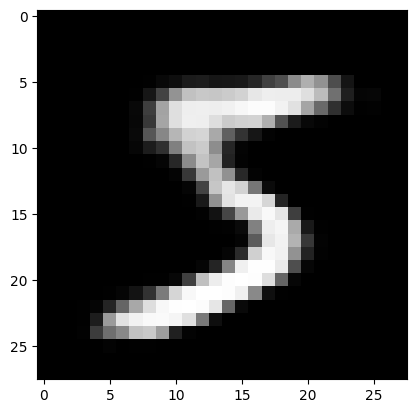

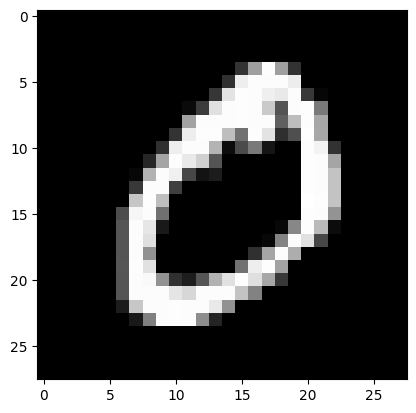

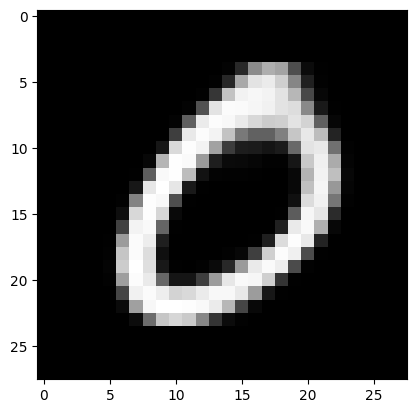

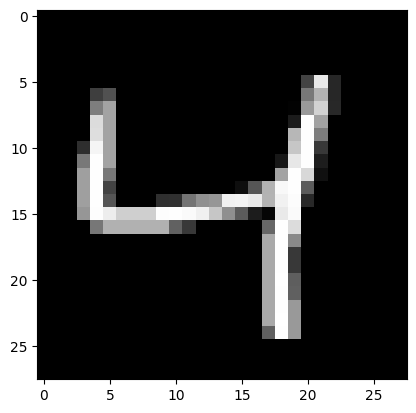

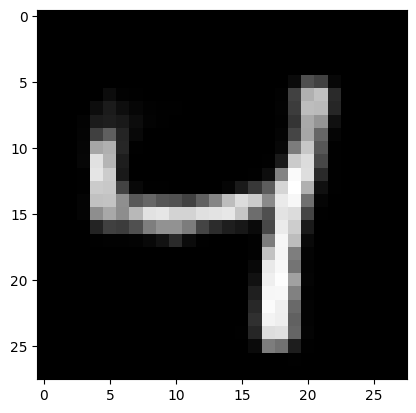

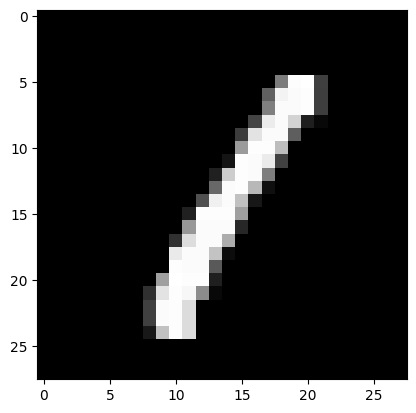

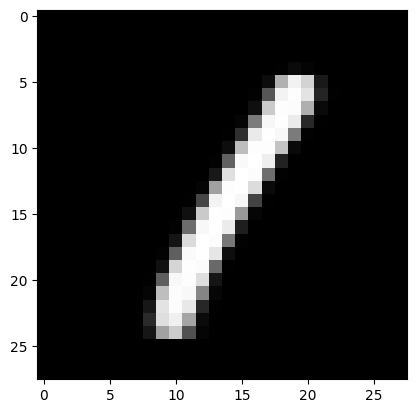

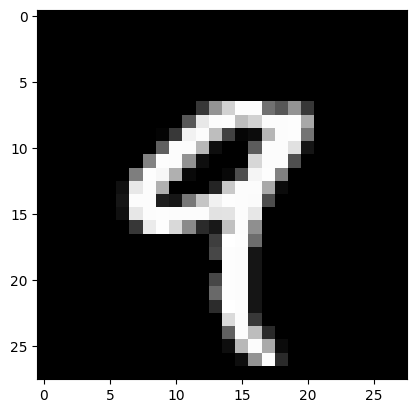

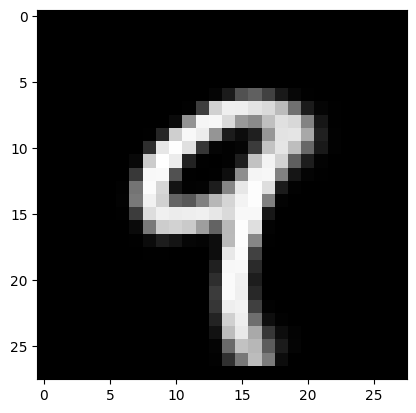

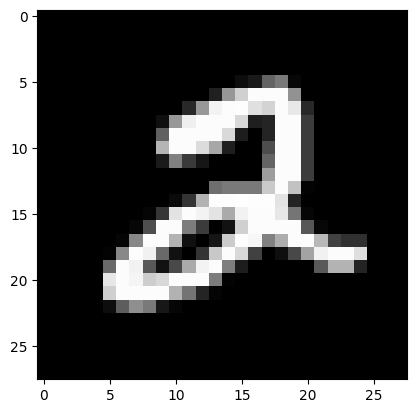

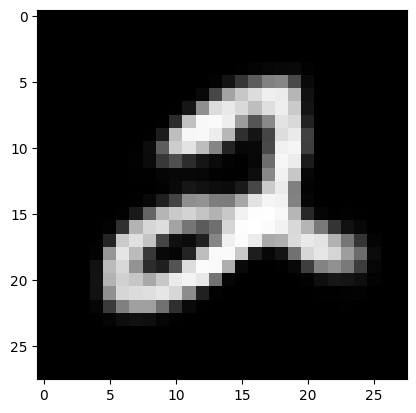

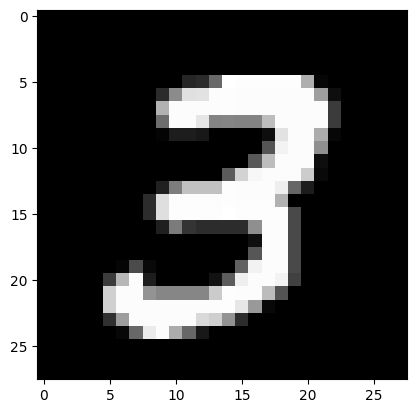

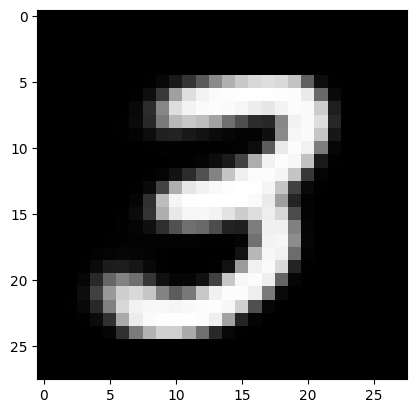

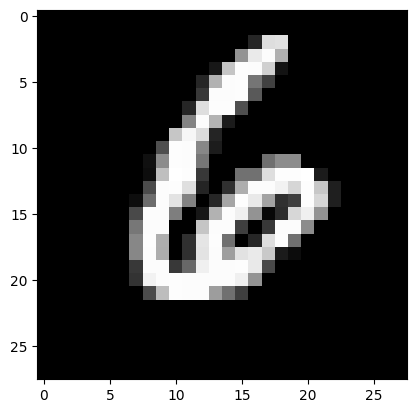

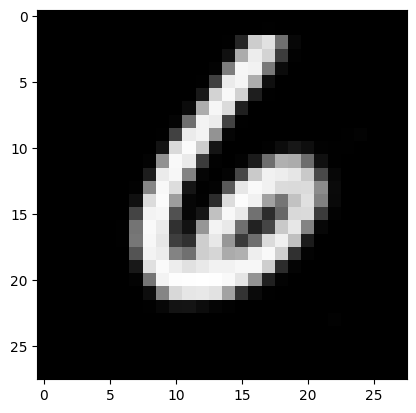

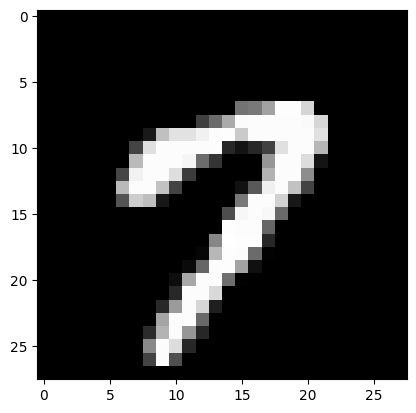

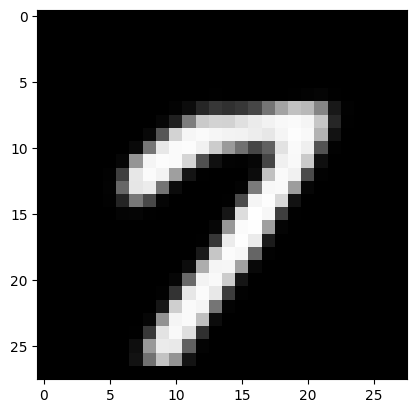

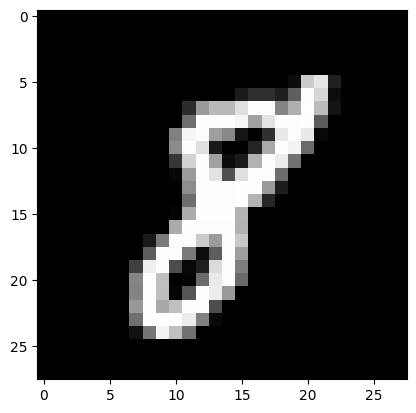

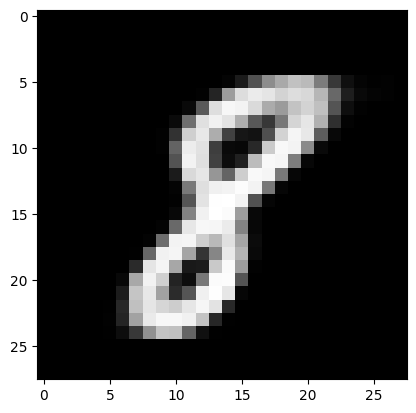

In [104]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		mu = model(image_tensor)[1]
		logits = model.decode(mu)
		reconstructed = torch.sigmoid(logits)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [105]:
model = VAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)[0]

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [106]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


"""scaler = StandardScaler()
Z = scaler.fit_transform(Z)"""

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [107]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.4787
NMI: 0.5383


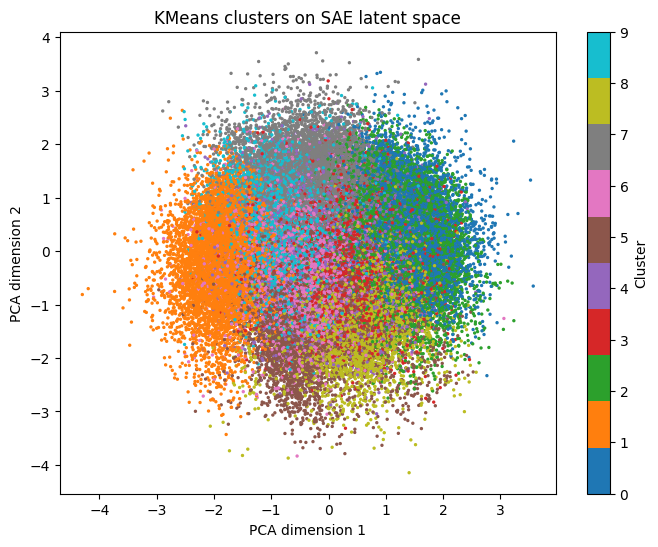

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on VAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

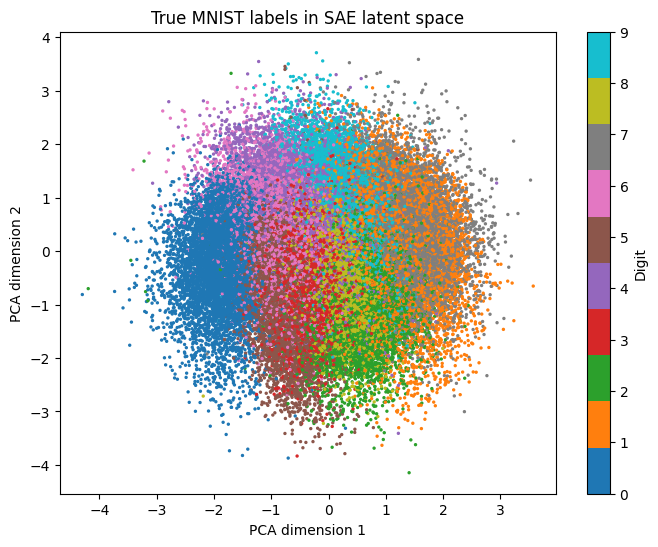

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in VAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [110]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


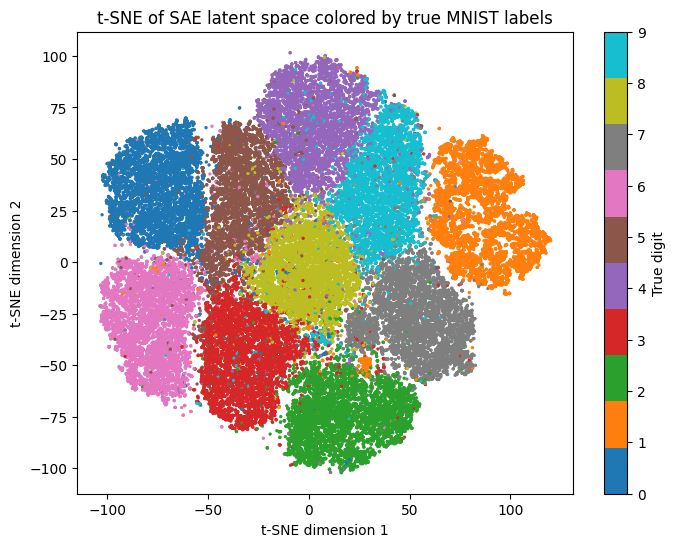

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of VAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

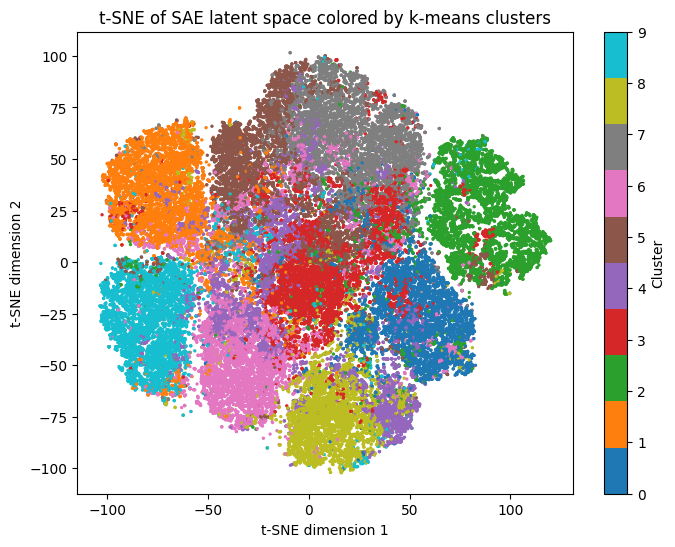

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of VAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [113]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.6424


In [114]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,1,18,129,41,14,10,0,5512,172,474
1,5931,0,5,121,4,752,231,4,79,6
2,0,7006,88,9,62,4,112,310,151,443
3,188,208,157,475,231,280,46,492,3936,1503
4,186,26,1546,1203,456,789,264,438,946,221
5,55,296,9,80,1772,3067,169,100,1049,472
6,305,40,160,4969,428,749,181,202,77,458
7,43,18,5,22,3775,343,41,81,103,3358
8,139,101,4745,200,42,19,28,140,198,17


In [115]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.02,0.01,0.00,0.00,0.00,0.87,0.03,0.07
1,0.83,0.00,0.00,0.02,0.00,0.11,0.03,0.00,0.01,0.00
2,0.00,0.86,0.01,0.00,0.01,0.00,0.01,0.04,0.02,0.05
3,0.03,0.03,0.02,0.06,0.03,0.04,0.01,0.07,0.52,0.20
4,0.03,0.00,0.25,0.20,0.08,0.13,0.04,0.07,0.16,0.04
5,0.01,0.04,0.00,0.01,0.25,0.43,0.02,0.01,0.15,0.07
6,0.04,0.01,0.02,0.66,0.06,0.10,0.02,0.03,0.01,0.06
7,0.01,0.00,0.00,0.00,0.48,0.04,0.01,0.01,0.01,0.43
8,0.02,0.02,0.84,0.04,0.01,0.00,0.00,0.02,0.04,0.00
